In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

h5 = h5py.File("../data/processed/paderborn.h5", "r")
print(list(h5.keys()))                 # all bearings
print(len(h5["KA08"]), "measurements in KA08")
print(h5.attrs.get("skipped_files"))

['K001', 'K002', 'K003', 'K004', 'K005', 'K006', 'KA01', 'KA03', 'KA04', 'KA05', 'KA06', 'KA07', 'KA08', 'KA09', 'KA15', 'KA16', 'KA22', 'KA30', 'KB23', 'KB24', 'KB27', 'KI01', 'KI03', 'KI04', 'KI05', 'KI07', 'KI08', 'KI14', 'KI16', 'KI17', 'KI18', 'KI21']
79 measurements in KA08
None


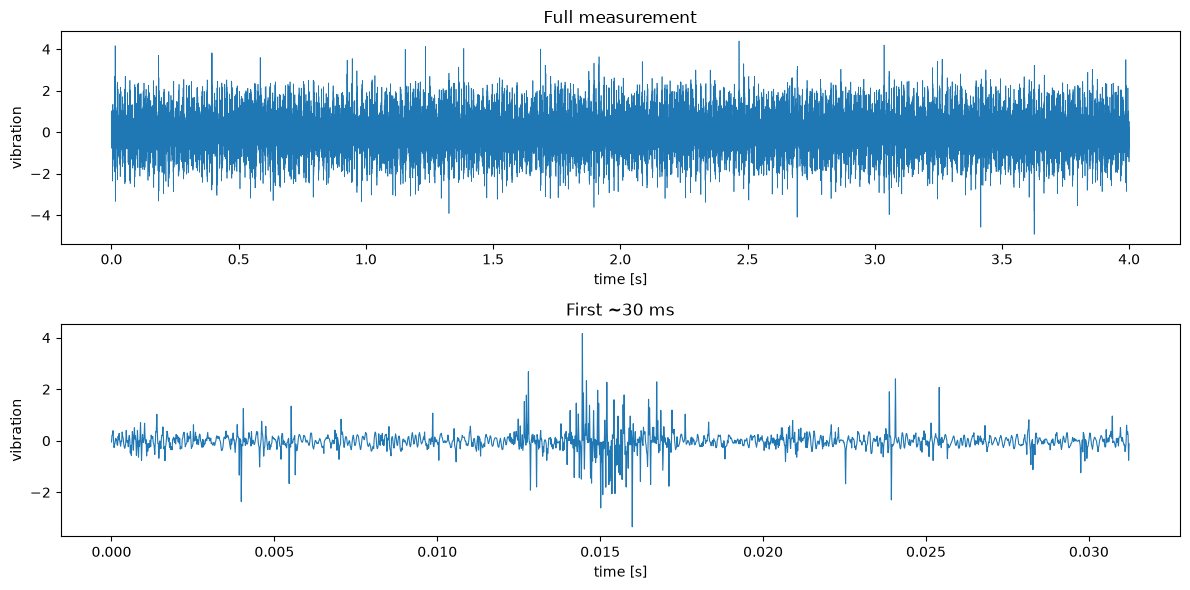

In [2]:
meas = h5["K001/N15_M07_F10_K001_1"]
x = meas["vibration_1"][:]
fs = meas["vibration_1"].attrs["fs"]
t = np.arange(len(x)) / fs

fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(t, x, lw=0.5)
ax[0].set(title="Full measurement", xlabel="time [s]", ylabel="vibration")
ax[1].plot(t[:2000], x[:2000], lw=0.8)
ax[1].set(title="First ~30 ms", xlabel="time [s]", ylabel="vibration")
plt.tight_layout()

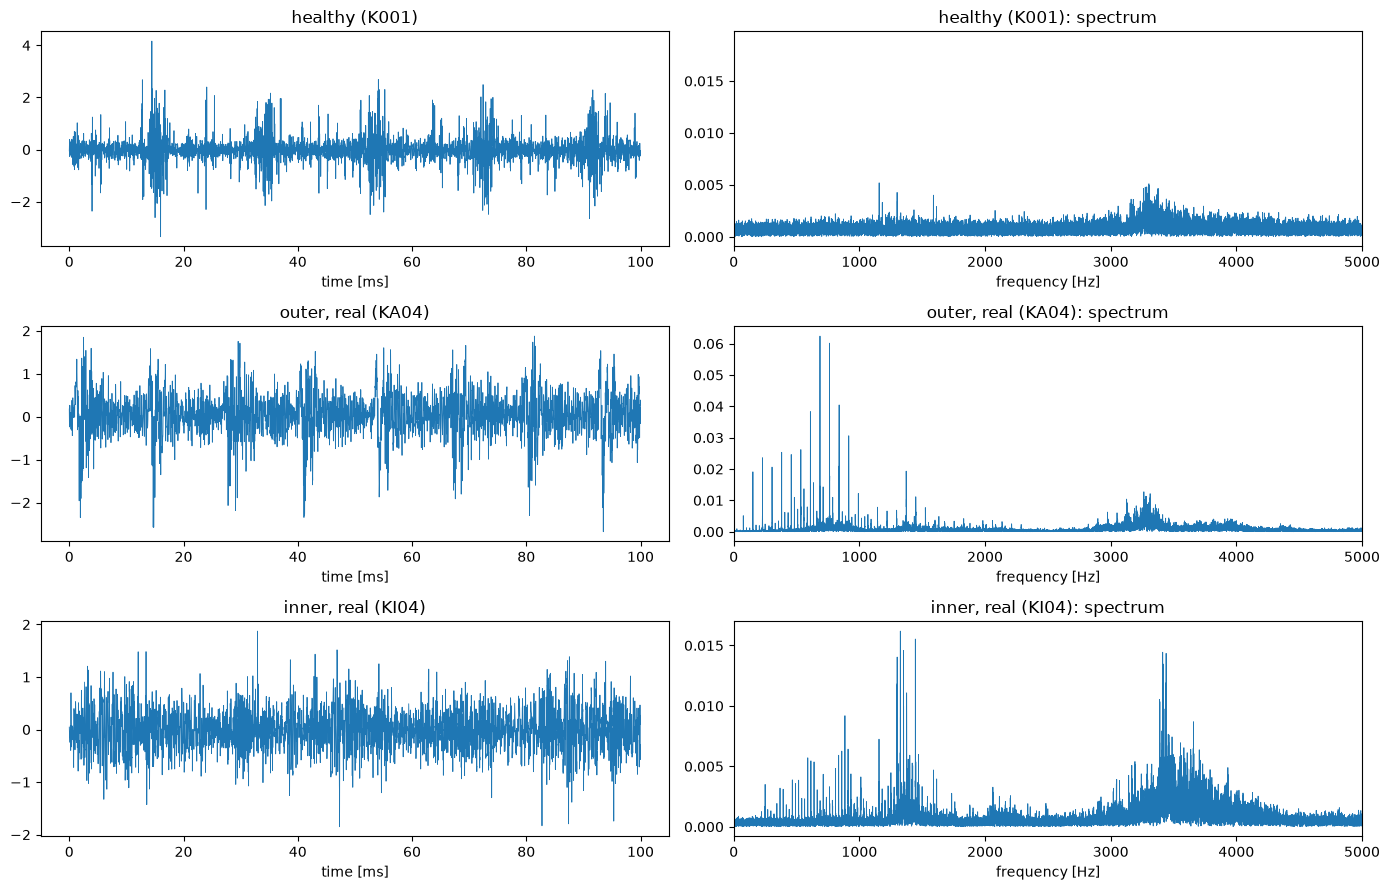

In [3]:
cases = {
    "healthy (K001)":     "K001/N15_M07_F10_K001_1",
    "outer, real (KA04)": "KA04/N15_M07_F10_KA04_1",
    "inner, real (KI04)": "KI04/N15_M07_F10_KI04_1",
}

fig, ax = plt.subplots(len(cases), 2, figsize=(14, 9))
for row, (label, path) in enumerate(cases.items()):
    x = h5[path]["vibration_1"][:]
    fs = h5[path]["vibration_1"].attrs["fs"]

    # time: 100 ms
    n = int(0.1 * fs)
    ax[row, 0].plot(np.arange(n) / fs * 1000, x[:n], lw=0.6)
    ax[row, 0].set(title=label, xlabel="time [ms]")

    # frequency: magnitude spectrum of the whole signal
    X = np.abs(np.fft.rfft(x)) / len(x)
    f = np.fft.rfftfreq(len(x), d=1 / fs)
    ax[row, 1].plot(f, X, lw=0.6)
    ax[row, 1].set(title=f"{label}: spectrum", xlabel="frequency [Hz]", xlim=(0, 5000))

plt.tight_layout()

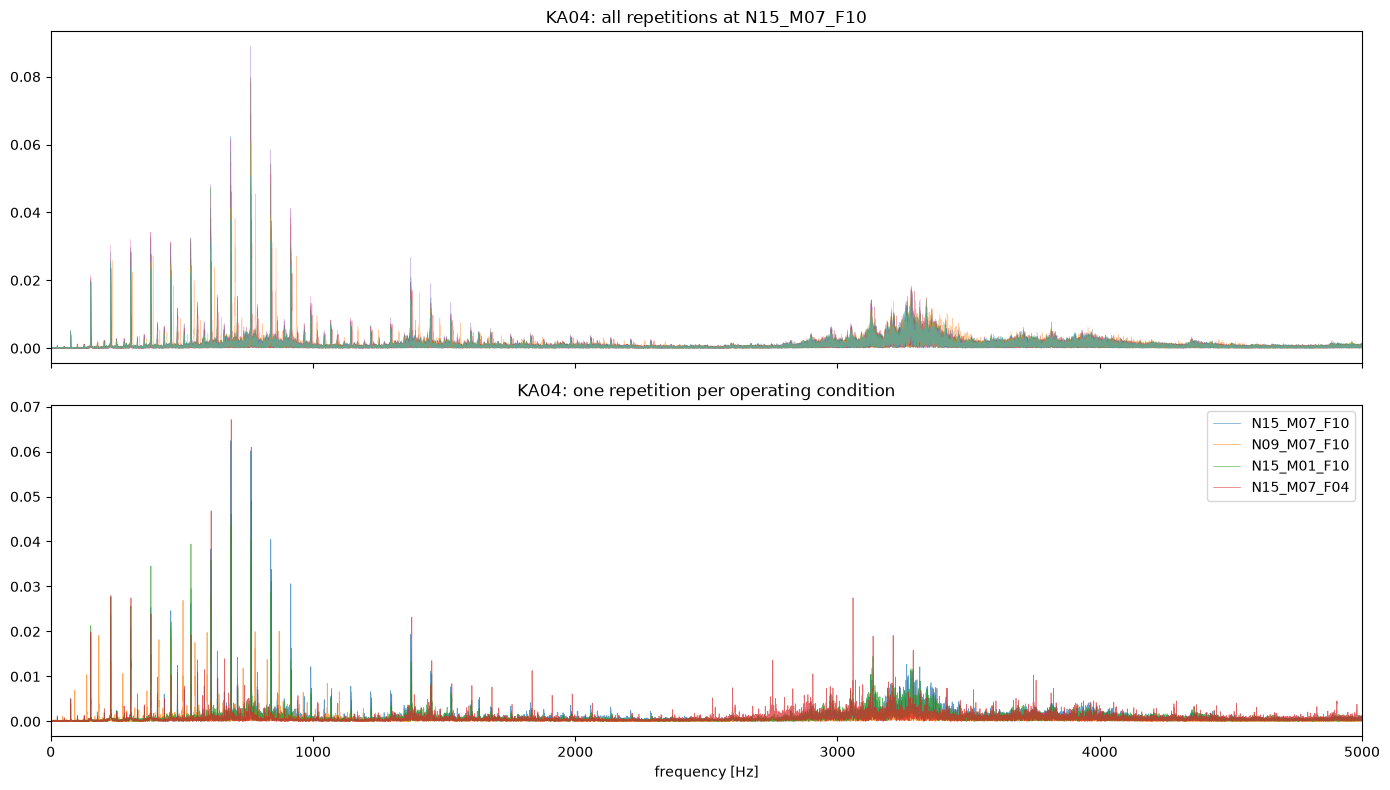

In [4]:
def spectrum(path, channel="vibration_1"):
    x = h5[path][channel][:]
    fs = h5[path][channel].attrs["fs"]
    return np.fft.rfftfreq(len(x), 1 / fs), np.abs(np.fft.rfft(x)) / len(x)

bearing = "KA04"
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

for name in h5[bearing]:
    if name.startswith("N15_M07_F10"):
        f, X = spectrum(f"{bearing}/{name}")
        ax[0].plot(f, X, lw=0.4, alpha=0.4)
ax[0].set(title=f"{bearing}: all repetitions at N15_M07_F10", xlim=(0, 5000))

for cond in ["N15_M07_F10", "N09_M07_F10", "N15_M01_F10", "N15_M07_F04"]:
    f, X = spectrum(f"{bearing}/{cond}_{bearing}_1")
    ax[1].plot(f, X, lw=0.5, alpha=0.7, label=cond)
ax[1].set(title=f"{bearing}: one repetition per operating condition", xlabel="frequency [Hz]")
ax[1].legend()
plt.tight_layout()


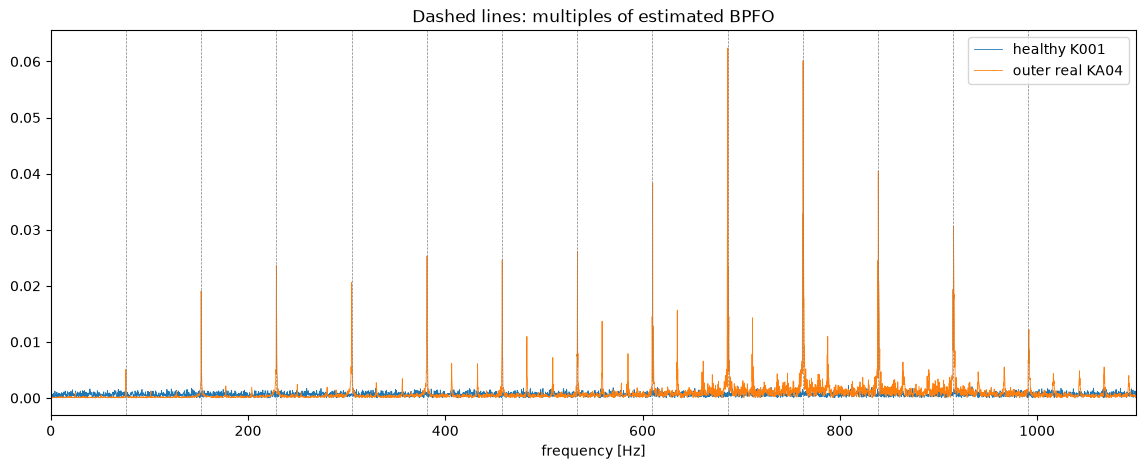

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
for path, label in [("K001/N15_M07_F10_K001_1", "healthy K001"),
                    ("KA04/N15_M07_F10_KA04_1", "outer real KA04")]:
    f, X = spectrum(path)
    ax.plot(f, X, lw=0.6, label=label)

bpfo = 3.05 * 1500 / 60          # ≈ 76 Hz
for k in range(1, 14):
    ax.axvline(k * bpfo, color="grey", ls="--", lw=0.5)

ax.set(xlim=(0, 1100), xlabel="frequency [Hz]", title="Dashed lines: multiples of estimated BPFO")
ax.legend()